In [3]:
#Packages
import os
import pandas as pd
from pathlib import Path

# Directory
directory = r"C:\Users\20234503\Desktop\Research\Weather and Strikes\Project\Results_2"

# Strikes
strikes_winter = pd.read_csv(os.path.join(directory, "Raw", "placebo_strike_1_r.csv"))
strikes_summer    = pd.read_csv(os.path.join(directory, "Raw", "placebo_strike_3_r.csv"))

def clean_df(df):
    # Rename columns
    df = df.rename(columns={
        "Unnamed: 0": "Variable",
        ".": "est",
        "Unnamed: 2": "se"
    })
    
    # Keep only the second row
    df = df.iloc[[2]].reset_index(drop=True)
    df["est"] = pd.to_numeric(df["est"], errors="coerce")
    df["se"] = pd.to_numeric(df["se"], errors="coerce")
    return df

strikes_summer = clean_df(strikes_summer)
strikes_winter = clean_df(strikes_winter)

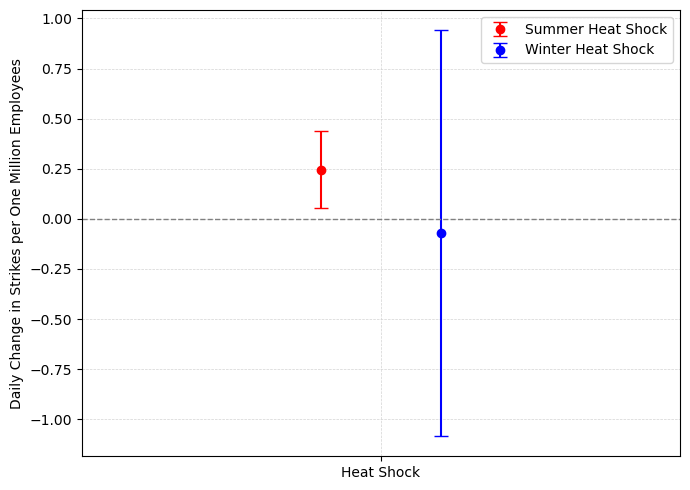

In [12]:
# Placebo test: Summer vs Winter effect of Heat Shocks
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --- Define thresholds and variable names (unchanged) ---
thresholds = {
    "Heat Shock": {"Summer": strikes_summer, "Winter": strikes_winter, "var": "hot_day"},
}

# Legend labels
season_labels = {
    "Summer": "Summer Heat Shock",
    "Winter": "Winter Heat Shock",
}

# Fixed colours for seasons
season_colors = {
    "Summer": "red",
    "Winter": "blue",
}

# --- Extract estimates & CIs from dataframes ---
rows = []

for thresh_label, info in thresholds.items():
    varname = info["var"]

    for season in ["Summer", "Winter"]:
        df = info[season]
        sub = df[df["Variable"] == varname]

        if sub.empty:
            print(f"⚠ Warning: {varname} not found in {season} at {thresh_label}")
            continue

        row = sub.iloc[0]
        est, se = row["est"], row["se"]

        ci_low  = est - 1.96 * se
        ci_high = est + 1.96 * se

        rows.append([thresh_label, season, est, ci_low, ci_high])

plot_df = pd.DataFrame(rows, columns=["threshold", "season", "est", "ci_low", "ci_high"])

# -------------------- PLOTTING --------------------

# Extract values
su = plot_df[plot_df["season"] == "Summer"].iloc[0]
wi = plot_df[plot_df["season"] == "Winter"].iloc[0]

# For readability
est_su, lo_su, hi_su = su["est"], su["ci_low"], su["ci_high"]
est_wi, lo_wi, hi_wi = wi["est"], wi["ci_low"], wi["ci_high"]

# Single x position
x_center = 0
delta = 0.03
x_summer = x_center - delta
x_winter = x_center + delta

fig, ax = plt.subplots(figsize=(7, 5))

# --- Summer (red) ---
ax.errorbar(
    [x_summer],
    [est_su],
    yerr=[[est_su - lo_su], [hi_su - est_su]],
    fmt="o",
    color=season_colors["Summer"],
    capsize=5,
    label=season_labels["Summer"],
)

# --- Winter (blue) ---
ax.errorbar(
    [x_winter],
    [est_wi],
    yerr=[[est_wi - lo_wi], [hi_wi - est_wi]],
    fmt="o",
    color=season_colors["Winter"],
    capsize=5,
    label=season_labels["Winter"],
)

# --- Formatting ---
ax.axhline(0, color="grey", linestyle="--", linewidth=1)
ax.grid(True, linestyle="--", linewidth=0.5, color="lightgrey")

ax.set_xticks([x_center])
ax.set_xticklabels(["Heat Shock"])
ax.set_xlim(x_center - 0.15, x_center + 0.15)

ax.set_ylabel("Daily Change in Strikes per One Million Employees")
ax.legend()

plt.tight_layout()
plt.show()


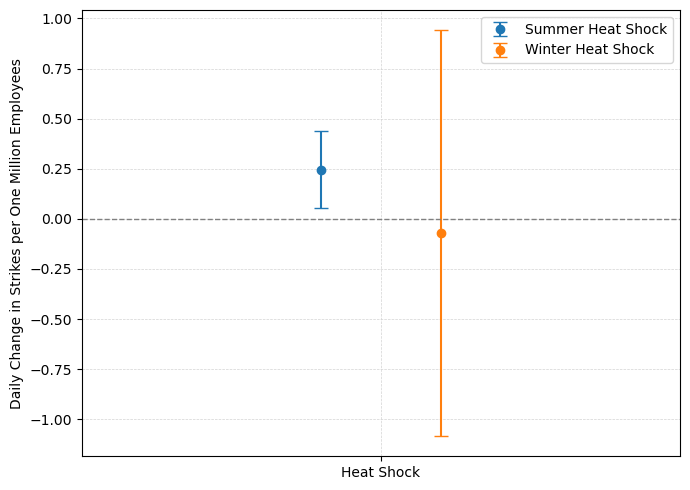

In [ ]:
# Placebo test: Summer vs Winter effect of Heat Shocks
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --- Define thresholds and variable names (unchanged) ---
thresholds = {
    "Heat Shock": {"Summer": strikes_summer, "Winter": strikes_winter, "var": "hot_day"},
    # if you have more thresholds, add them here, e.g.
    # "≥ 2 SD":   {"Summer": strikes_summer_2sd, "Winter": strikes_winter_2sd, "var": "hot_day"},
    # "≥ 2.5 SD": {"Summer": strikes_summer_25sd, "Winter": strikes_winter_25sd, "var": "hot_day"},
    # ...
}

# Labels for the legend
season_labels = {
    "Summer": "Summer Heat Shock",
    "Winter": "Winter Heat Shock",
}

# --- Extract rows for plotting (now just Summer/Winter) ---
rows = []

for thresh_label, info in thresholds.items():
    varname = info["var"]

    for season in ["Summer", "Winter"]:
        df = info[season]
        sub = df[df["Variable"] == varname]

        if sub.empty:
            print(f"⚠ Warning: {varname} not found in {season} at {thresh_label}")
            continue

        row = sub.iloc[0]
        est = row["est"]
        se = row["se"]

        ci_low = est - 1.96 * se
        ci_high = est + 1.96 * se

        rows.append([
            thresh_label,
            season,
            est,
            ci_low,
            ci_high,
        ])

plot_df = pd.DataFrame(
    rows,
    columns=["threshold", "season", "est", "ci_low", "ci_high"]
)

# -------------------- PLOTTING --------------------

# Order thresholds on x-axis
threshold_list = list(plot_df["threshold"].unique())
# If you want a specific order, uncomment and adapt:
# threshold_list = ["Heat Shock", "≥ 2 SD", "≥ 2.5 SD", "≥ 3 SD"]

x = np.arange(len(threshold_list))

# Colours for the two series
season_colors = {
    "Summer": "tab:red",
    "Winter": "tab:blue",
}

# pull the two estimates out of whatever dataframes you have
# (replace these lines with your actual lookups)
su = plot_df[plot_df["season"] == "Summer"].iloc[0]
wi = plot_df[plot_df["season"] == "Winter"].iloc[0]

est_su, lo_su, hi_su = su["est"], su["ci_low"], su["ci_high"]
est_wi, lo_wi, hi_wi = wi["est"], wi["ci_low"], wi["ci_high"]

fig, ax = plt.subplots(figsize=(7, 5))

x_center  = 0.0        # where the tick "Heat Shock" goes
delta     = 0.03       # how far apart the two points are
x_summer  = x_center - delta
x_winter  = x_center + delta

# Summer
ax.errorbar(
    [x_summer],
    [est_su],
    yerr=[[est_su - lo_su], [hi_su - est_su]],
    fmt="o",
    capsize=5,
    label="Summer Heat Shock",
)

# Winter
ax.errorbar(
    [x_winter],
    [est_wi],
    yerr=[[est_wi - lo_wi], [hi_wi - est_wi]],
    fmt="o",
    capsize=5,
    label="Winter Heat Shock",
)

# cosmetics
ax.axhline(0, color="grey", linestyle="--", linewidth=1)
ax.grid(True, linestyle="--", linewidth=0.5, color="lightgrey")

ax.set_xticks([x_center])
ax.set_xticklabels(["Heat Shock"])
ax.set_xlim(x_center - 0.15, x_center + 0.15)  # ensures the small delta is visible

ax.set_ylabel("Daily Change in Strikes per One Million Employees")
ax.legend()

plt.tight_layout()
plt.show()
